# Notebook 03 — FlashAttention forward pass, from scratch

**Project:** Reimplement the algorithm of *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness* (Dao et al., 2022).  
**Target hardware:** Apple M5 (the first implementation is educational NumPy; optional PyTorch/MPS checks follow).  
**Prerequisite:** Notebook 02 — online softmax.

## Learning goals
1. Write the scaled dot-product attention reference and identify its quadratic score storage.
2. Partition queries, keys, and values into tiles.
3. Maintain numerically stable **per-query-row** online-softmax statistics while streaming K/V tiles.
4. Implement an **exact (up to rounding)** tiled attention forward pass without allocating an $N_q\times N_k$ attention matrix.
5. Add causal masking, prove correctness numerically, examine intermediate states, and distinguish a **NumPy prototype** from a **fused GPU kernel**.

> **Important:** This notebook reproduces the mathematical/algorithmic structure of FlashAttention-1's forward pass. NumPy slicing and matrix multiplications are **not** a fused GPU kernel and **will not by themselves deliver FlashAttention's GPU speedups**. That is our next milestone.

## 0. Setup and notation

For one attention head:

$$
Q\in\mathbb{R}^{N_q\times d},\quad K\in\mathbb{R}^{N_k\times d},\quad V\in\mathbb{R}^{N_k\times d_v}.
$$

$$
S=\frac{QK^\top}{\sqrt d},\qquad O=\mathrm{softmax}_{\mathrm{row}}(S)V.
$$

We use **float64** for the first proofs to isolate algorithmic correctness from lower-precision rounding. The implementation supports separate query and key lengths and value dimensions. For causal masking in this notebook, assume **self-attention** ($N_q=N_k$) and allow key position $j$ only when $j\le i$.

In [1]:
import math
import time
import numpy as np

np.set_printoptions(precision=5, suppress=True)
rng = np.random.default_rng(2026)
print("NumPy:", np.__version__)


NumPy: 2.5.4


## 1. Reference: standard attention

In the textbook implementation, the score matrix $S$ and (usually) the probability matrix $P$ are $N_q\times N_k$. They consume $\Theta(N_qN_k)$ elements, even though the final output has only $N_q\times d_v$ elements. The crucial FlashAttention improvement is to avoid writing these quadratic intermediates to high-bandwidth memory.

### Visualization A — How tiling changes the attention computation

Each **blue rectangle** is one `(block_q × block_k)` score tile. A conventional implementation materializes the entire `Nq × Nk` score matrix; this educational tiled implementation materializes only one small score tile at a time. Follow the numbered tiles in execution order (outer loop: query tile; inner loop: key tile).

Matplotlib is building the font cache; this may take a moment.


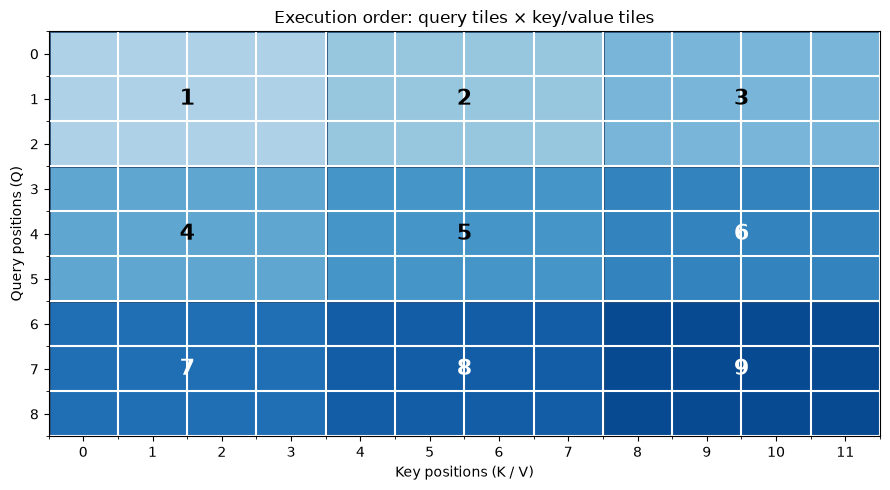

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

nq, nk, bq, bk = 9, 12, 3, 4
fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xlim(0, nk); ax.set_ylim(nq, 0)
ax.set_xticks(np.arange(nk) + 0.5, labels=np.arange(nk))
ax.set_yticks(np.arange(nq) + 0.5, labels=np.arange(nq))
ax.set_xlabel('Key positions (K / V)'); ax.set_ylabel('Query positions (Q)')
ax.set_title('Execution order: query tiles × key/value tiles')
ax.set_xticks(np.arange(nk + 1), minor=True); ax.set_yticks(np.arange(nq + 1), minor=True)
ax.grid(which='minor', color='white', linewidth=1.5)
step = 0
for q0 in range(0, nq, bq):
    for k0 in range(0, nk, bk):
        step += 1
        color = plt.cm.Blues(0.25 + 0.65 * step / 9)
        ax.add_patch(Rectangle((k0, q0), min(bk,nk-k0), min(bq,nq-q0), facecolor=color, edgecolor='#234d78', lw=2))
        ax.text(k0 + bk/2, q0 + bq/2, f'{step}', ha='center', va='center', fontsize=16,
                color='white' if step > 5 else 'black', fontweight='bold')
fig.tight_layout(); plt.show()

In [3]:
def stable_softmax(scores, axis=-1):
    """Stable row-wise softmax for matrices with >=1 valid entry per row."""
    maxima = np.max(scores, axis=axis, keepdims=True)
    weights = np.exp(scores - maxima)
    return weights / np.sum(weights, axis=axis, keepdims=True)


def reference_attention(q, k, v, *, causal=False):
    """Materializes all scores and probabilities. Educational oracle."""
    nq, d = q.shape
    nk, dk = k.shape
    assert d == dk and nk == v.shape[0]
    if causal:
        assert nq == nk, "This notebook uses square causal self-attention."
    scores = (q @ k.T) / np.sqrt(d)
    if causal:
        i = np.arange(nq)[:, None]
        j = np.arange(nk)[None, :]
        scores = np.where(j <= i, scores, -np.inf)
    probabilities = stable_softmax(scores)
    return probabilities @ v

q = rng.normal(size=(7, 4))
k = rng.normal(size=(7, 4))
v = rng.normal(size=(7, 3))
print('noncausal output shape:', reference_attention(q,k,v).shape)
print('causal first row (must equal v[0]):', reference_attention(q,k,v,causal=True)[0])
np.testing.assert_allclose(reference_attention(q,k,v,causal=True)[0], v[0], atol=1e-14)


noncausal output shape: (7, 3)
causal first row (must equal v[0]): [-0.29043  0.28383  1.28808]


## 2. The row-wise online-softmax invariant

For each query row $i$, after scanning **some** keys $J$, we maintain:

$$
m_i=\max_{j\in J}s_{ij},\qquad
\ell_i=\sum_{j\in J}e^{s_{ij}-m_i},\qquad
\mathbf a_i=\sum_{j\in J}e^{s_{ij}-m_i}\mathbf v_j.
$$

After all keys are processed, $\mathbf o_i=\mathbf a_i/\ell_i$.

**Merge in a K/V tile:** let $S_b\in\mathbb R^{B_q\times B_k}$ be scores for a block of $B_q$ queries against $B_k$ keys. Then

$$
\begin{aligned}
m_i' &= \max\left(m_i, \max_{j\in\text{tile}} (S_b)_{ij}\right),\\
\alpha_i &= e^{m_i-m_i'},\\
P_{ij}^{(b)} &= e^{(S_b)_{ij}-m_i'},\\
\ell_i' &= \alpha_i\ell_i + \sum_{j\in\text{tile}}P_{ij}^{(b)},\\
\mathbf a_i' &= \alpha_i\mathbf a_i + \sum_{j\in\text{tile}}P_{ij}^{(b)}\mathbf v_j.
\end{aligned}
$$

The rescaling $\alpha_i$ is essential: if a later tile has a larger score, old contributions must be expressed relative to the **new** maximum. We initialize $m_i=-\infty$, $\ell_i=0$, $\mathbf a_i=0$.

## 3. The complete tiled algorithm

Two nested loops:

- **Outer loop over Q tiles:** each query tile has its own vectors of running maxima \(m\), normalizers \(\ell\), and accumulators \(A\).
- **Inner loop over K/V tiles:** compute only a \(B_q\times B_k\) score tile, merge into the running state, then discard the score tile.

**Pseudocode**

```text
for q_start in range(0, Nq, Bq):
    Qb = Q[q_start : q_start+Bq]
    m = [-inf] * rows(Qb)
    l = [0] * rows(Qb)
    A = zeros(rows(Qb), dv)

    for k_start in range(0, Nk, Bk):
        Kb, Vb = K[k_start : k_start+Bk], V[k_start : k_start+Bk]
        S = (Qb @ Kb.T) / sqrt(d)
        optionally mask future keys
        new_m = maximum(m, rowmax(S))
        alpha = exp(m - new_m)  # old-state rescaling
        P = exp(S - new_m[:, None])
        l = alpha*l + rowsum(P)
        A = alpha[:, None]*A + P @ Vb
        m = new_m

    output[q_start : q_start+Bq] = A / l[:, None]
```

The code below also handles a fully masked **individual tile row** safely, avoiding \(-\infty-(-\infty)\) NaNs. In square causal attention, tile blocks entirely above the diagonal can be skipped.

In [16]:
def tiled_attention(q, k, v, *, block_q=32, block_k=32, causal=False,
                    return_debug=False):
    """Educational FlashAttention-style forward pass with NumPy.

    Allocates score/probability tiles of at most (block_q, block_k),
    never an (Nq, Nk) score matrix. Runs a single attention head.
    Accumulates in the dtype of q, k, and v (use float64 initially).
    """
    q, k, v = np.asarray(q), np.asarray(k), np.asarray(v)
    assert q.ndim == k.ndim == v.ndim == 2
    nq, d = q.shape
    nk, dk = k.shape
    assert d == dk and v.shape[0] == nk
    assert nq > 0 and nk > 0 and block_q > 0 and block_k > 0
    assert q.dtype == k.dtype == v.dtype, "Use a common dtype in this tutorial."
    assert np.issubdtype(q.dtype, np.floating)
    if causal:
        assert nq == nk, "Causal mode here requires Nq == Nk."
    dv = v.shape[1]
    out = np.empty((nq, dv), dtype=q.dtype)
    debug = []
    inv_sqrt_d = 1.0 / math.sqrt(d)

    for q0 in range(0, nq, block_q):
        q1 = min(q0 + block_q, nq)
        qb = q[q0:q1]     # (bq, d)
        bq = q1 - q0
        m = np.full(bq, -np.inf, dtype=q.dtype)
        ell = np.zeros(bq, dtype=q.dtype)
        acc = np.zeros((bq, dv), dtype=q.dtype)

        for k0 in range(0, nk, block_k):
            k1 = min(k0 + block_k, nk)
            # Every key in this tile is in the future for every query row.
            if causal and k0 >= q1:
                break

            kb, vb = k[k0:k1], v[k0:k1]
            scores = (qb @ kb.T) * inv_sqrt_d  # (bq, bk)
            if causal:
                query_positions = np.arange(q0, q1)[:, None]
                key_positions = np.arange(k0, k1)[None, :]
                scores = np.where(key_positions <= query_positions,
                                  scores, -np.inf)

            block_max = np.max(scores, axis=1)
            new_m = np.maximum(m, block_max)

            # For rows with no valid key seen yet, define their old
            # scale and new probabilities to be zero (not NaN).
            alpha = np.zeros_like(m)
            valid_old = np.isfinite(m) & np.isfinite(new_m)
            alpha[valid_old] = np.exp(m[valid_old] - new_m[valid_old])

            p = np.zeros_like(scores)
            valid_new = np.isfinite(new_m)
            p[valid_new] = np.exp(scores[valid_new] - new_m[valid_new, None])

            ell = alpha * ell + p.sum(axis=1)
            acc = alpha[:, None] * acc + p @ vb
            m = new_m

            if return_debug:
                debug.append(dict(q_tile=(q0, q1), kv_tile=(k0, k1),
                                  m=m.copy(), ell=ell.copy(), acc=acc.copy()))

        if not np.all(ell > 0):
            raise ValueError('Attention row without valid keys; cannot normalize')
        out[q0:q1] = acc / ell[:, None]

    return (out, debug) if return_debug else out


## 4. First verification: odd sizes, different tile sizes

Small and uneven dimensions are useful: they expose off-by-one errors on the final partial tile. \(B_q\) and \(B_k\) are independent.

In [17]:
rng = np.random.default_rng(17)
q = rng.normal(size=(11, 7))
k = rng.normal(size=(13, 7))
v = rng.normal(size=(13, 5))
expected = reference_attention(q, k, v)

for bq, bk in [(1, 1), (2, 3), (4, 5), (8, 4), (16, 32)]:
    observed = tiled_attention(q, k, v, block_q=bq, block_k=bk)
    err = np.max(np.abs(observed - expected))
    print(f'Bq={bq:2d}, Bk={bk:2d} | max abs error={err:.3e}')
    np.testing.assert_allclose(observed, expected, rtol=1e-12, atol=1e-12)
print('✓ Noncausal tiled output matches reference for all tile sizes.')


Bq= 1, Bk= 1 | max abs error=6.661e-16
Bq= 2, Bk= 3 | max abs error=2.220e-16
Bq= 4, Bk= 5 | max abs error=4.441e-16
Bq= 8, Bk= 4 | max abs error=3.331e-16
Bq=16, Bk=32 | max abs error=2.220e-16
✓ Noncausal tiled output matches reference for all tile sizes.


## 5. Inspect the state after each K/V tile

For a single query, print $m$, $\ell$, and the current result $a/\ell$. The final value should match the reference row. Notice that a larger maximum may appear in a later tile—earlier values are rescaled accordingly.

In [18]:
q_demo = np.array([[1., 0.]])
k_demo = np.array([[1., 0.], [2., 0.], [9., 0.], [0., 1.], [3., 0.]])
v_demo = np.array([[1., 0.], [2., 0.], [3., 1.], [4., 0.], [5., 0.]])
result, trace = tiled_attention(q_demo, k_demo, v_demo,
                                block_q=1, block_k=2, return_debug=True)
for step, state in enumerate(trace, start=1):
    print(f"tile {step} {state['kv_tile']}: m={state['m'][0]:.4f}, "
          f"ell={state['ell'][0]:.4f}, o={state['acc'][0] / state['ell'][0]}")
print('reference:', reference_attention(q_demo, k_demo, v_demo)[0])
np.testing.assert_allclose(result, reference_attention(q_demo, k_demo, v_demo), atol=1e-14)


tile 1 (0, 2): m=1.4142, ell=1.4931, o=[1.66976 0.     ]
tile 2 (2, 4): m=6.3640, ell=1.0123, o=[2.9878  0.98785]
tile 3 (4, 5): m=6.3640, ell=1.0267, o=[3.01596 0.97402]
reference: [3.01596 0.97402]


## 6. Causal attention: tile-wise and element-wise masking

For **causal self-attention**, query $i$ may attend to keys $j\le i$. A tile above the diagonal contains no valid pairs and can be skipped. A tile that crosses the diagonal must be **masked within the tile**. Masked scores are $-\infty$, so their exponential is zero. A whole tile row can be masked, which is why our update has guards against $-\infty-(-\infty)$.

> Later: support for non-square causal attention needs an explicit alignment convention; we intentionally avoid silently choosing one here.

### Visualization B — Watch online softmax converge tile by tile

We reuse the trace from Section 5. The scores include a **large value in the second K/V tile**, forcing the previous accumulator and denominator to be rescaled. The left plot tracks the running maximum and denominator; the right plot tracks the intermediate attention output (one line per value dimension). The dashed lines show the dense reference output.

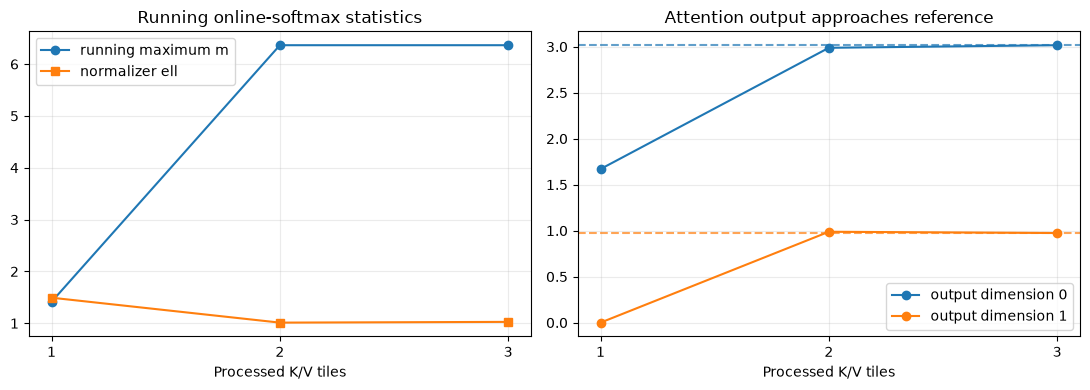

final output: [3.01596 0.97402] 
reference:    [3.01596 0.97402]


In [19]:
steps = np.arange(1, len(trace) + 1)
maxima = np.array([st['m'][0] for st in trace])
denoms = np.array([st['ell'][0] for st in trace])
outputs = np.stack([st['acc'][0] / st['ell'][0] for st in trace])
reference = reference_attention(q_demo, k_demo, v_demo)[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(steps, maxima, 'o-', label='running maximum m')
axes[0].plot(steps, denoms, 's-', label='normalizer ell')
axes[0].set(xlabel='Processed K/V tiles', title='Running online-softmax statistics')
axes[0].legend(); axes[0].grid(alpha=0.25)
for dim in range(v_demo.shape[1]):
    line, = axes[1].plot(steps, outputs[:, dim], 'o-', label=f'output dimension {dim}')
    axes[1].axhline(reference[dim], color=line.get_color(), linestyle='--', alpha=0.7)
axes[1].set(xlabel='Processed K/V tiles', title='Attention output approaches reference')
axes[1].legend(); axes[1].grid(alpha=0.25)
for ax in axes: ax.set_xticks(steps)
fig.tight_layout(); plt.show()
print('final output:', outputs[-1], '\nreference:   ', reference)
np.testing.assert_allclose(outputs[-1], reference, atol=1e-14)

In [20]:
rng = np.random.default_rng(56)
for n in [1, 2, 3, 11, 18]:
    q = rng.normal(size=(n, 8))
    k = rng.normal(size=(n, 8))
    v = rng.normal(size=(n, 6))
    expected = reference_attention(q, k, v, causal=True)
    for bq, bk in [(1, 1), (3, 2), (5, 7), (32, 32)]:
        got = tiled_attention(q, k, v, block_q=bq, block_k=bk, causal=True)
        np.testing.assert_allclose(got, expected, rtol=1e-12, atol=1e-12)
    np.testing.assert_allclose(expected[0], v[0], atol=1e-13)
print('✓ Causal masking works for small, odd, and partial tiles.')


✓ Causal masking works for small, odd, and partial tiles.


## 7. Numerical stability stress test

A naive \(e^s\) implementation can overflow. Our implementation always subtracts a running maximum. Test **large scores**, where naive exponentiation would fail.

### Visualization C — Causal mask and tile boundaries

For causal self-attention, query position `i` may only see key positions `j ≤ i`. **Green** cells are allowed and **light gray** cells are masked. The thick tile boundaries show that some tiles are wholly valid, some are wholly skipped, and diagonal-crossing tiles need element-wise masking.

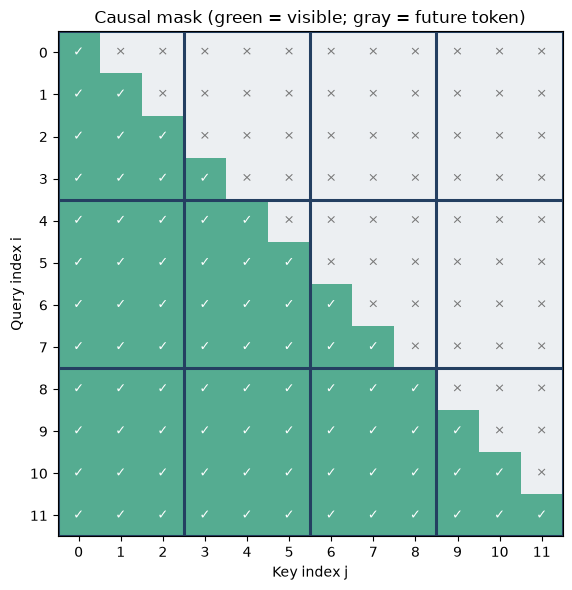

In [21]:
from matplotlib.colors import ListedColormap

n, bq, bk = 12, 4, 3
allowed = (np.arange(n)[None, :] <= np.arange(n)[:, None]).astype(int)
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(allowed, cmap=ListedColormap(['#eceff2', '#55ac91']), vmin=0, vmax=1)
for x in np.arange(-0.5, n, bk): ax.axvline(x, color='#243f61', lw=2.2)
for y in np.arange(-0.5, n, bq): ax.axhline(y, color='#243f61', lw=2.2)
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set(xlabel='Key index j', ylabel='Query index i',
       title='Causal mask (green = visible; gray = future token)')
for i in range(n):
    for j in range(n):
        ax.text(j, i, '✓' if allowed[i,j] else '×', va='center', ha='center',
                fontsize=9, color='white' if allowed[i,j] else '#777777')
fig.tight_layout(); plt.show()

In [22]:
q = np.array([[1000.], [-1000.], [2000.]])
k = np.array([[1.], [-1.], [0.5], [2.], [-0.5]])
v = np.array([[1., 0.], [0., 1.], [3., 4.], [-1., 2.], [9., 2.]])
ref = reference_attention(q, k, v)
out = tiled_attention(q, k, v, block_q=2, block_k=2)
print('Output:', out)
print('All finite:', np.isfinite(out).all())
np.testing.assert_allclose(out, ref, rtol=1e-12, atol=1e-12)


Output: [[-1.  2.]
 [ 0.  1.]
 [-1.  2.]]
All finite: True


## 8. Memory accounting: what is and isn't eliminated?

For a single head:

| Quantity | Reference | Tiled prototype |
|---|---:|---:|
| Attention scores | $N_q N_k$ | $B_qB_k$ at a time |
| Softmax probabilities | $N_q N_k$ | $B_qB_k$ at a time |
| Per-query state | not required as a separate state | $B_q$ maxima, $B_q$ normalizers, $B_qd_v$ accumulators |
| Final output | $N_qd_v$ | $N_qd_v$ |

The whole input $Q,K,V$ is still required. The main win is avoiding **quadratic intermediate storage**. In our NumPy prototype, tile intermediates are allocated and Python loops introduce overhead. In the real GPU kernel, the score tiles and state reside in efficient on-chip storage (subject to hardware/resource constraints), and operations are fused.

For intuition, compare the **number of score elements** (this is not a measurement of actual peak RAM).

In [23]:
def score_storage_example(nq, nk, bq, bk, bytes_per_element=4):
    full = nq * nk * bytes_per_element
    tile = min(nq, bq) * min(nk, bk) * bytes_per_element
    return full, tile

n = 4096
full, tile = score_storage_example(n, n, 64, 64)
print(f'One full score matrix: {full / 2**20:.2f} MiB')
print(f'One score tile:         {tile / 2**10:.2f} KiB')
print(f'Ratio:                  {full / tile:,.0f}x fewer score elements at once')
print('Note: the reference typically also allocates a probability matrix.')


One full score matrix: 64.00 MiB
One score tile:         16.00 KiB
Ratio:                  4,096x fewer score elements at once
Note: the reference typically also allocates a probability matrix.


## 9. Optional: compare with PyTorch on your M5 (MPS)

**Device check:** compare NumPy tiled attention to PyTorch's dense reference running on MPS. This validates our output against a separate implementation, but it does **not** make NumPy tiled attention GPU-accelerated. We use float32 and a looser tolerance to account for different arithmetic order and accelerator rounding. If PyTorch is missing, the cell will print an explanation instead of failing.

### Visualization D — Score-memory scaling with sequence length

The chart compares storage for a **single dense score matrix** (`N×N`) with a **single 64×64 score tile** in float32. This is *not* total peak-process memory: Q/K/V, output, row statistics, Python arrays, and GPU implementation overhead are not included. The prototype's tile allocation is constant at fixed block sizes, while dense score storage grows quadratically.

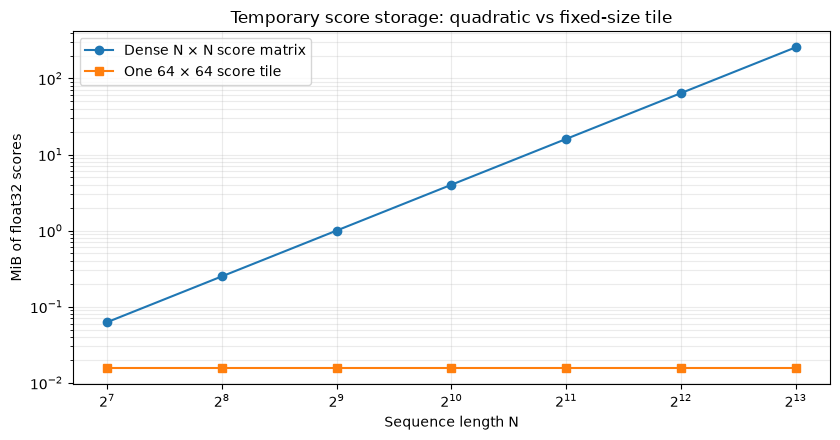

In [24]:
seq_lengths = np.array([128, 256, 512, 1024, 2048, 4096, 8192])
full_mib = seq_lengths.astype(np.float64)**2 * 4 / 2**20
tile_mib = np.minimum(seq_lengths,64).astype(np.float64)**2 * 4 / 2**20
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(seq_lengths, full_mib, 'o-', label='Dense N × N score matrix')
ax.plot(seq_lengths, tile_mib, 's-', label='One 64 × 64 score tile')
ax.set(xlabel='Sequence length N', ylabel='MiB of float32 scores',
       title='Temporary score storage: quadratic vs fixed-size tile')
ax.set_yscale('log'); ax.set_xscale('log', base=2)
ax.grid(alpha=0.25, which='both'); ax.legend()
fig.tight_layout(); plt.show()

In [25]:
try:
    import torch
    print('PyTorch:', torch.__version__, '| MPS:', torch.backends.mps.is_available())
    if torch.backends.mps.is_available():
        rng = np.random.default_rng(333)
        q_np = rng.normal(size=(128, 32)).astype(np.float32)
        k_np = rng.normal(size=(128, 32)).astype(np.float32)
        v_np = rng.normal(size=(128, 24)).astype(np.float32)
        tiled_np = tiled_attention(q_np, k_np, v_np, block_q=16, block_k=32)
        q_t = torch.from_numpy(q_np).to('mps')
        k_t = torch.from_numpy(k_np).to('mps')
        v_t = torch.from_numpy(v_np).to('mps')
        dense_mps = torch.softmax((q_t @ k_t.T) / math.sqrt(32), dim=-1) @ v_t
        dense_np = dense_mps.cpu().numpy() # transfer back for comparison
        print('max |NumPy tiled - MPS dense|:', np.max(np.abs(tiled_np - dense_np)))
        np.testing.assert_allclose(tiled_np, dense_np, rtol=3e-4, atol=3e-4)
        print('✓ MPS cross-check passed.')
    else:
        print('MPS not available on this host; skipping GPU check.')
except ImportError:
    print('PyTorch not installed here; optional MPS check skipped.')


PyTorch: 2.14.1 | MPS: True
max |NumPy tiled - MPS dense|: 2.9802322e-07
✓ MPS cross-check passed.


## 10. Timing experiment (do **not** interpret as a GPU benchmark)

Compare the dense NumPy implementation and our educational tiled NumPy implementation. Dense NumPy delegates large matrix operations to optimized numerical libraries; the tiled version uses many small operations and Python loops. **It is normal and expected for the tiled NumPy version to be slower**. FlashAttention's speedups require a genuinely fused, hardware-aware GPU implementation.

In [26]:
rng = np.random.default_rng(911)
n, d, dv = 256, 32, 32
q = rng.normal(size=(n, d))
k = rng.normal(size=(n, d))
v = rng.normal(size=(n, dv))

for name, fn in [
    ('dense NumPy', lambda: reference_attention(q, k, v)),
    ('tiled NumPy', lambda: tiled_attention(q, k, v, block_q=32, block_k=64)),
]:
    times = []
    for _ in range(3):
        t0 = time.perf_counter()
        _ = fn()
        times.append(time.perf_counter() - t0)
    print(f'{name:12s} median of 3: {np.median(times)*1000:.2f} ms')

np.testing.assert_allclose(reference_attention(q,k,v),
                           tiled_attention(q,k,v,block_q=32,block_k=64),
                           rtol=1e-12, atol=1e-12)


dense NumPy  median of 3: 0.52 ms
tiled NumPy  median of 3: 1.74 ms


## 11. A small randomized test suite

Check output shapes, heterogeneous dimensions, partial tiles, and causal/noncausal modes. This is the start of the test suite for our future package.

In [27]:
rng = np.random.default_rng(2027)
checks = 0
for nq, nk, d, dv in [(1, 1, 1, 1), (7, 13, 5, 3), (19, 4, 8, 11), (32, 32, 16, 9)]:
    q = rng.normal(size=(nq, d))
    k = rng.normal(size=(nk, d))
    v = rng.normal(size=(nk, dv))
    for causal in ([False, True] if nq == nk else [False]):
        for bq, bk in [(1, 1), (3, 5), (16, 7), (128, 128)]:
            ref = reference_attention(q, k, v, causal=causal)
            got = tiled_attention(q, k, v, block_q=bq, block_k=bk,
                                  causal=causal)
            assert got.shape == (nq, dv)
            np.testing.assert_allclose(got, ref, rtol=1e-12, atol=1e-12)
            checks += 1
print(f'✓ {checks} tiled-attention comparisons passed.')


✓ 24 tiled-attention comparisons passed.


## 12. What have we actually achieved?

**We have:**
- Implemented the mathematically exact **forward attention** computation via tiled score matrices.
- Kept running **per-row** \(m,\ell,a\) online-softmax statistics.
- Supported noncausal cross-attention and square causal self-attention.
- Tested numerical equivalence for partial tiles, large scores, and several shapes.

**We have not yet:**
- Fused computations into one Apple GPU kernel.
- Validated performance or *actual* peak GPU memory usage.
- Implemented backward propagation, batch/head dimensions, dropout, or all masking conventions.

## Exercises

**A — Pencil-and-paper:** For one query with scores \([1, 4, 2, 7]\), process two tiles of size 2. Compute \(m,\ell\) after the first tile and after merging the second. Verify the final denominator against stable softmax.

**B — Trace:** Run `tiled_attention(..., return_debug=True)` with \(B_q=2,B_k=3\) and print the first query row's \(m,\ell\) after every tile. Compare the partial \(a/\ell\) to dense attention restricted to the keys seen so far.

**C — Causality:** Set \(Q=K=0\). With causal masking, show that row \(i\) returns the average of \(V[0:i+1]\), regardless of tile size.

**D — API:** Extend the function to take arrays of shape \((B,H,N,d)\) by looping over batches and heads. Keep the single-head implementation as the tested inner kernel.

**E — Performance prediction:** For \(N=8192, B_q=64,B_k=64\) and float32 scores, calculate the full-score versus tile-score element count. Explain why this is *not* by itself a prediction of wall-clock speed.

## Next: Notebook 04 — Apple GPU kernel

We will first map each concept to Apple Silicon (SIMD groups, threadgroups, threadgroup memory, and unified memory), then implement a **custom Metal or MLX GPU kernel**. We'll benchmark its results with synchronization and compare against Apple's/PyTorch's optimized attention operators. Aim for correctness first; tile selection and fusion follow.

**Paper reference:** Dao et al., *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness* (NeurIPS 2022), Algorithm 1.